# Torsion preprocessing

What happens to the torsions before either clustering method sees them, and how a clustered frame is
written for a histogram. A torsion is measured through four **named** atoms, and a molecular symmetry
renames atoms without moving any: paracetamol's ring flip renames C5 as C10, so one configuration is
`aryl = -16` degrees measured through C5 and `aryl = 164` degrees measured through C10. Anything built on
the stored columns has to know that, or it calls one configuration two.

```text
the selected torsions + the molecule + the coordinates
  -> enumerate the symmetry (on the canonicalised graph)             section 2, 3
  -> close the descriptor under it, weight each orbit               section 4
       -> HDBSCAN:            the symmetric distance d_sym           section 5
       -> torsion partitioning:  symmetry-invariant coordinates         section 6
  -> for drawing: every frame in the labelling nearest one reference  section 7, 8
```

**Relabelling is not motion.** No atom moves, no frame is added or dropped, and nothing is merged after a
fit. The same minimum over the symmetry operations gives a symmetry-corrected RMSD (section 9).

The example is paracetamol: the 1 us cMD run of the [paracetamol tutorial](https://csy0000.github.io/MD-tools/tutorial/paracetamol/),
every 25th frame (4000 frames), three torsions. Section 3 also uses c(RGDfV), whose carboxylate and
guanidinium need the canonical form.

In [1]:
import os, sys, pathlib, tempfile
sys.path.insert(0, str(pathlib.Path.cwd().parents[2] / "tutorial" / "_analysis"))   # docs/tutorial/_analysis

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mdtraj as md
from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG, Image, display
import tutorial_data as td
import md_tools
from md_tools.analysis import (TorsionDefinitions, SymmetricTorsionDescriptor, enumerate_symmetry,
                               verify_atom_mapping, draw_torsions, draw_symmetry_operation, t_hdbscan,
                               cut_clustering, group_name)

# Where the data are is NOT printed: these pages are committed with their outputs.
print("tutorial runs:", "found" if td.runs_root().is_dir() else "MISSING", "| md-tools", md_tools.__version__)
scratch = pathlib.Path(tempfile.mkdtemp())          # figures that a helper writes to disk
palette = plt.get_cmap("tab10")
wrap = lambda x: np.angle(np.exp(1j * x))

tutorial runs: found | md-tools 0.6.5.2


## 1. The torsions and what has to come with them

Angles alone cannot establish a symmetry, so the default route needs:

| input | what it is | when |
|---|---|---|
| `torsions` | `(n_frames, n_selected)` stored angles, in the order of the definitions | always |
| `molecule` | an RDKit molecule with explicit hydrogens (the SDF the system was built from) | always |
| `torsion_definitions` | a `TorsionDefinitions` indexing that molecule | always |
| `coordinates` | an `mdtraj.Trajectory`, or an `(n, n_atoms, 3)` array with `box_vectors` (or `periodic=False`) and a `topology` | when a symmetry maps a selected torsion onto one that is not in the table |
| `atom_mapping` | the trajectory index of each molecule atom; never defaulted | with `coordinates` |

Missing information raises with the call that fixes it, and nothing falls back to ordinary clustering on its
own (`symmetry=False` says so explicitly). The mapping is checked twice: by graph (elements and every bond
among the mapped atoms) and by geometry (each stored column must agree with the same quadruplet recomputed
from the coordinates, to 1e-3 rad). A molecule split across the periodic box is made whole along its bonds
before any dihedral is computed.

CC(=O)Nc1ccc(O)cc1 | 20 atoms | 4000 frames
atom mapping: identity | identity verified: elements and the full bond graph agree under this mapping


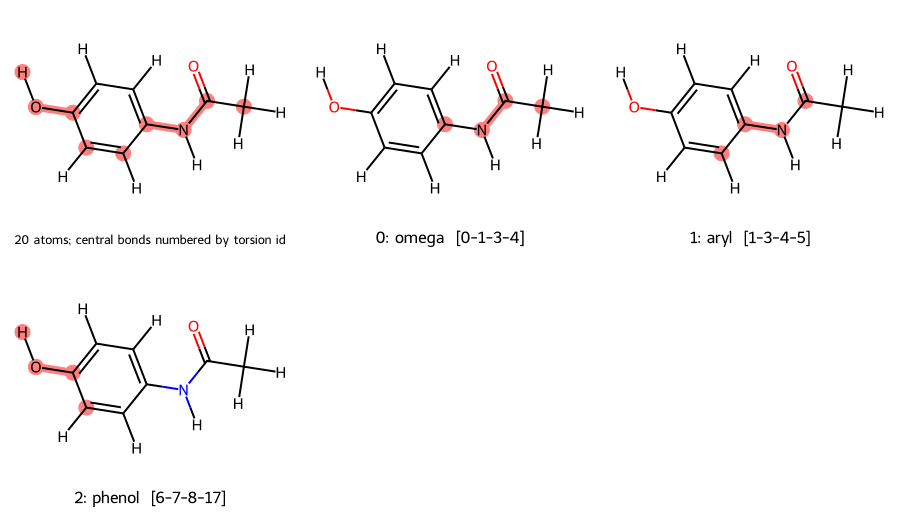

In [2]:
mol = Chem.SDMolSupplier(str(td.run_dir("PARA-REST2") / "build/TYL.sdf"), removeHs=False)[0]
TORSIONS = {"omega": (0, 1, 3, 4), "aryl": (1, 3, 4, 5), "phenol": (6, 7, 8, 17)}
definitions = TorsionDefinitions(quads=tuple(TORSIONS.values()), names=tuple(TORSIONS),
                                 indexing="zero-based", units="radian")
cmd = td.solute("PARA-1us", stride=25)
tors = md.compute_dihedrals(cmd, list(TORSIONS.values()))
mapping, why = verify_atom_mapping(mol, [(b[0].index, b[1].index) for b in cmd.topology.bonds],
                                   [a.element.symbol for a in cmd.topology.atoms])
print(Chem.MolToSmiles(Chem.RemoveHs(mol)), "|", mol.GetNumAtoms(), "atoms |", len(tors), "frames")
print("atom mapping:", "identity" if mapping == list(range(mol.GetNumAtoms())) else mapping, "|", why)
draw_torsions(mol, definitions, output=str(scratch / "torsions.svg"))
display(SVG(filename=str(scratch / "torsions.svg")))

`omega` is the amide (0-1-3-4), `aryl` the bond joining the amide to the ring (1-3-4-5) and `phenol` the
hydroxyl rotation (6-7-8-17).

## 2. Enumerating the symmetry

A symmetry operation is an atom permutation that preserves the chemical graph: element, bond order, formal
charge, isotope and any specified stereochemistry. RDKit finds every one by matching the molecule against
**itself** (`uniquify=False`, `useChirality=True`), for the whole molecule: rings, methyl groups, anything.
`enumerate_symmetry` does that on a copy with atom-map numbers cleared, re-verifies each match as an element-
and bond-order-preserving bijection, checks that every specified stereocentre keeps its CIP label, puts the
identity first, and asks for one match more than its cap (200 000): a search that hits the cap raises
`IncompleteSymmetryEnumeration` instead of being used. Each permutation reads "atom *i* goes to atom `p[i]`".

In [3]:
enumeration = enumerate_symmetry(mol)
raw = enumeration.permutations
print(f"automorphisms: {enumeration.order}")
for p in (raw[0], raw[1], raw[6], raw[7]):
    moved = {i: j for i, j in enumerate(p) if i != j}
    print(" ", tuple(p), "  moved:", moved if moved else "nothing (identity)")

automorphisms: 12
  (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19)   moved: nothing (identity)
  (0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 12, 14, 15, 16, 17, 18, 19)   moved: {12: 13, 13: 12}
  (0, 1, 2, 3, 4, 10, 9, 7, 8, 6, 5, 11, 12, 13, 14, 19, 18, 17, 16, 15)   moved: {5: 10, 6: 9, 9: 6, 10: 5, 15: 19, 16: 18, 18: 16, 19: 15}
  (0, 1, 2, 3, 4, 10, 9, 7, 8, 6, 5, 11, 13, 12, 14, 19, 18, 17, 16, 15)   moved: {5: 10, 6: 9, 9: 6, 10: 5, 12: 13, 13: 12, 15: 19, 16: 18, 18: 16, 19: 15}


Twelve permutations: the three methyl hydrogens (11, 12, 13) in any of 3! = 6 orders, times the ring flip
that exchanges C5 with C10, C6 with C9, and their hydrogens. The amide, the ring's para axis and the hydroxyl
stay where they are.

## 3. Canonicalization: atoms the drawing keeps apart

A graph with localised bond orders and charges draws a carboxylate as `C=O` and `C-O-`. Matched as drawn,
the two oxygens are different atoms, so no permutation exchanges them, and a torsion measured to one oxygen
is never folded onto the torsion measured to the other, half a turn away. The same holds for the two
terminal nitrogens of a guanidinium.

`enumerate_symmetry` therefore **canonicalises** the molecule first (`canonicalize=True`, the default): the
charge of each atom and the order of each bond are averaged over the resonance structures RDKit's
`ResonanceMolSupplier` generates, and two atoms with the same averaged values, the same element and the
same neighbours are one atom. A molecule with no delocalised group gets back exactly its own integers.
Three rules keep it from over-reaching: **aromatic atoms and bonds keep their own values** (the supplier
returns a ring Kekulised, and averaging 1 and 2 would break the ring's own flip); **the structure count is a
limit that refuses** (`max_structures`), because a result at the limit cannot be told from a truncated one;
and **every returned permutation is re-verified** against the averaged values. RDKit does not generate the
alternative drawings of a hypervalent group, so one rule is added: the terminal oxygens (or sulfurs) of a
sulfur, phosphorus or chlorine centre are one atom.

Each group below is drawn as the structures RDKit generates and then as the canonical form the search
compares; the highlighted atoms become exchangeable. In the guanidinium the substituted nitrogen shares the
charge and the bond orders too, but keeps its own neighbour, so only the two terminal nitrogens exchange.

Carboxylate (propionate): the two oxygens are exchanged


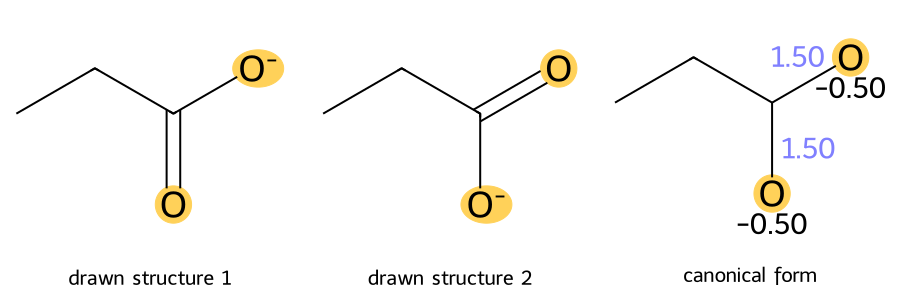

Guanidinium (ethylguanidinium): the two terminal nitrogens are exchanged


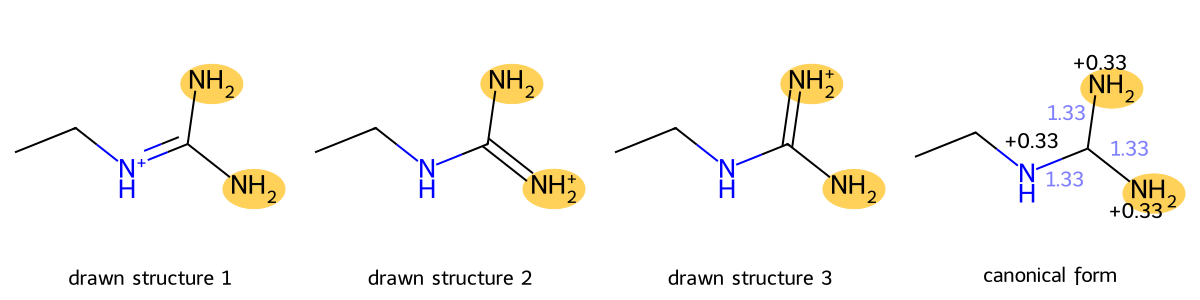

In [4]:
from rdkit.Chem import rdDepictor
from md_tools.analysis import resonance_hybrid

def draw_canonicalization(smiles, exchanged):
    """The drawn resonance structures of a model of the group, then its canonical form."""
    model = Chem.AddHs(Chem.MolFromSmiles(smiles))
    supplier = Chem.ResonanceMolSupplier(model)
    forms = [Chem.RemoveHs(supplier[i]) for i in range(len(supplier))]
    for f in forms:
        rdDepictor.Compute2DCoords(f)
    info = resonance_hybrid(model)
    canonical = Chem.RWMol(Chem.RemoveHs(Chem.Mol(model)))
    rdDepictor.Compute2DCoords(canonical)
    for a in canonical.GetAtoms():
        q = info.atom_charge[a.GetIdx()]
        a.SetFormalCharge(0)
        if abs(q) > 1e-9:
            a.SetProp("atomNote", f"{q:+.2f}")
    for b in canonical.GetBonds():
        o = info.bond_order[(min(b.GetBeginAtomIdx(), b.GetEndAtomIdx()), max(b.GetBeginAtomIdx(), b.GetEndAtomIdx()))]
        b.SetBondType(Chem.BondType.SINGLE)
        if abs(o - 1.0) > 1e-9:
            b.SetProp("bondNote", f"{o:.2f}")
    mols = forms + [canonical.GetMol()]
    legends = [f"drawn structure {i + 1}" for i in range(len(forms))] + ["canonical form"]
    drawer = rdMolDraw2D.MolDraw2DCairo(300 * len(mols), 300, 300, 300)
    drawer.drawOptions().legendFontSize = 20
    drawer.drawOptions().annotationFontScale = 0.8
    colour = {i: (1.0, 0.82, 0.35) for i in exchanged}
    drawer.DrawMolecules(mols, legends=legends, highlightAtoms=[list(exchanged)] * len(mols),
                         highlightAtomColors=[colour] * len(mols), highlightBonds=[[]] * len(mols))
    drawer.FinishDrawing()
    return drawer.GetDrawingText()

print("Carboxylate (propionate): the two oxygens are exchanged")
display(Image(data=draw_canonicalization("CCC(=O)[O-]", [3, 4])))
print("Guanidinium (ethylguanidinium): the two terminal nitrogens are exchanged")
display(Image(data=draw_canonicalization("CCNC(N)=[NH2+]", [4, 5])))

Measured automorphism counts, drawn structure against canonical form (hydrogens explicit):

| group | example | drawn | canonical |
|---|---|---|---|
| carboxylate | acetate | 6 | 12 |
| carboxylate on a ring | benzoate | 2 | 4 |
| guanidinium | N-methylguanidinium | 24 | 48 |
| amidinium | acetamidinium | 24 | 48 |
| nitro | nitromethane | 6 | 12 |
| nitrate | nitrate | 2 | 6 |
| carbonate | carbonate | 2 | 6 |
| sulfonate (rule) | methanesulfonate | 12 | 36 |
| phosphate monoester (rule) | methyl phosphate | 12 | 36 |
| unchanged | acetic acid, acetamide, urea, phenol, paracetamol, phenolate, an asymmetric azide | = | = |

**On real data.** c(RGDfV) has an Asp carboxylate and an Arg guanidinium. With Asp `chi2` (CA-CB-CG-O)
and the guanidinium torsion Arg `chi5` (CD-NE-CZ-NH) among the selected torsions, the drawn structure has 4
operations on them and the canonical form 16: the phenyl flip, the valine methyls, the carboxylate and the
guanidinium, in every combination. Below, the state-0 ensemble of the registered REST2 dataset (three runs,
every 75th frame, 4002 frames), as stored and with every frame in one labelling (section 7):

drawn structure :  4 operations, 21 columns
canonical form  : 16 operations, 23 columns


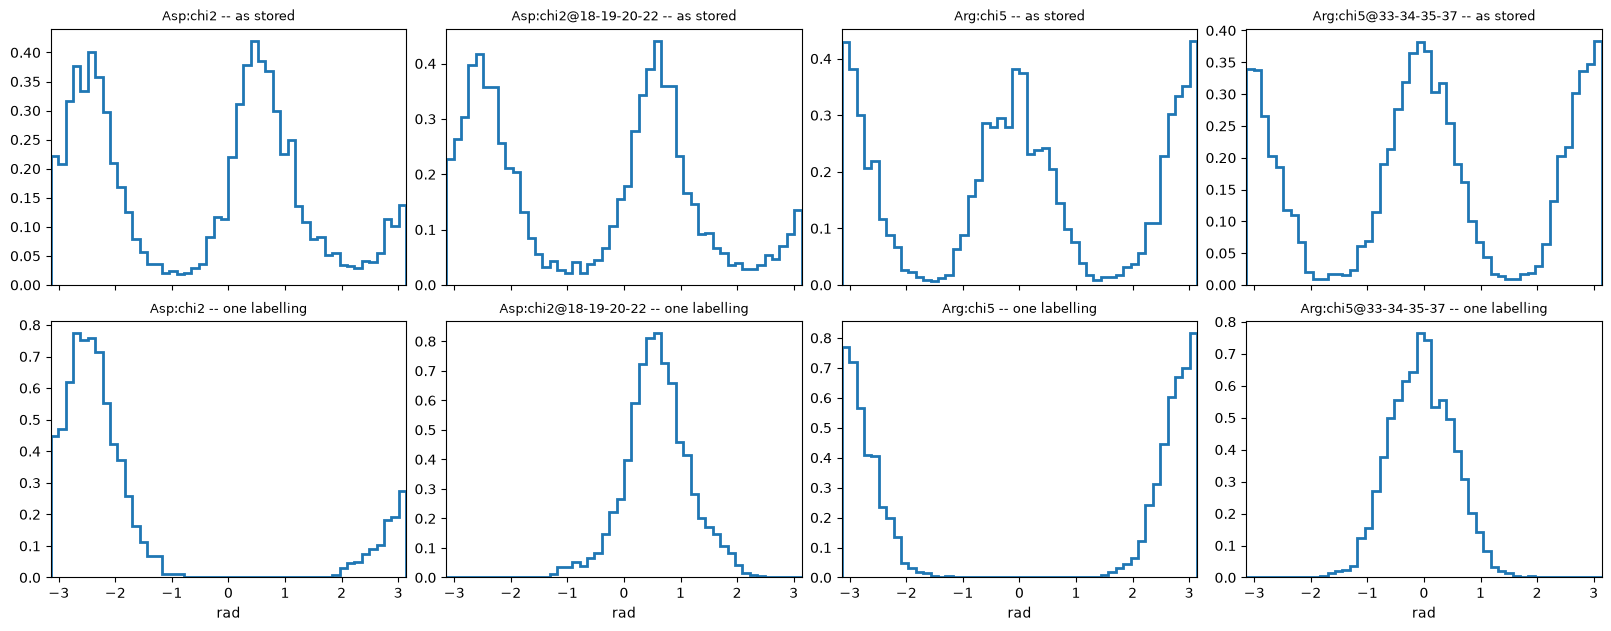

In [5]:
ROOT = pathlib.Path(os.environ["MD_DATA"]) / "2026/hpREST2/RGDfV-explicit-HMR-REST2"
rmol = Chem.SDMolSupplier(str(ROOT / "system/built.sdf"), removeHs=False)[0]
parts = [md.load(str(ROOT / f"REST2-run{r}/md_script/solute_state0_prod1.nc"),
                 top=str(ROOT / "system/built.solute.pdb"))[::75] for r in (1, 2, 3)]
rtraj = parts[0].join(parts[1]).join(parts[2])
rmap, _ = verify_atom_mapping(rmol, [(b[0].index, b[1].index) for b in rtraj.topology.bonds],
                              [a.element.symbol for a in rtraj.topology.atoms])
RGD19 = {"Val:phi": (5, 4, 3, 39), "Val:psi": (4, 3, 39, 38), "Val:omega": (3, 39, 38, 30),
         "Phe:phi": (16, 15, 7, 5), "Phe:psi": (15, 7, 5, 4), "Phe:omega": (7, 5, 4, 3),
         "Asp:phi": (24, 23, 18, 16), "Asp:psi": (23, 18, 16, 15), "Asp:omega": (18, 16, 15, 7),
         "Gly:phi": (28, 27, 26, 24), "Gly:psi": (27, 26, 24, 23), "Gly:omega": (26, 24, 23, 18),
         "Arg:phi": (39, 38, 30, 28), "Arg:psi": (38, 30, 28, 27), "Arg:omega": (30, 28, 27, 26),
         "Val:chi1": (4, 3, 1, 0), "Phe:chi2": (7, 8, 9, 10), "Asp:chi2": (18, 19, 20, 21), "Arg:chi5": (33, 34, 35, 36)}
rdefs = TorsionDefinitions(quads=tuple(RGD19.values()), names=tuple(RGD19), indexing="zero-based", units="radian")
drawn = SymmetricTorsionDescriptor(rmol, rdefs, canonicalize=False)
canon = SymmetricTorsionDescriptor(rmol, rdefs)
print(f"drawn structure : {len(drawn.operations):2d} operations, {drawn.n_columns} columns")
print(f"canonical form  : {len(canon.operations):2d} operations, {canon.n_columns} columns")
rfit = t_hdbscan(md.compute_dihedrals(rtraj, list(RGD19.values())), molecule=rmol, torsion_definitions=rdefs,
                 coordinates=rtraj, atom_mapping=rmap).fit()
ral = rfit.align_all(per_cluster=True)
edges = np.linspace(-np.pi, np.pi, 49)
fig, axes = plt.subplots(2, 4, figsize=(16, 6.2), layout="constrained", sharex=True)
for r, (title, theta) in enumerate((("as stored", rfit.closed_theta_), ("one labelling", ral["angles"]))):
    for j, name in enumerate(["Asp:chi2", "Asp:chi2@18-19-20-22", "Arg:chi5", "Arg:chi5@33-34-35-37"]):
        col = canon.names.index(name)
        axes[r, j].hist(theta[:, col], bins=edges, density=True, histtype="step", lw=2.0, color=palette(0))
        axes[r, j].set_xlim(-np.pi, np.pi); axes[r, j].set_title(f"{name} -- {title}", fontsize=9)
for j in range(4):
    axes[1, j].set_xlabel("rad")
plt.show()

Stored, each column has two peaks half a turn apart that are one state seen through either oxygen, or
either nitrogen. In one labelling each has one.

**What canonicalization does not cover.** Tautomers are not resonance: moving a hydrogen (imidazole N-H,
keto-enol) changes the graph, and a tautomer is a different molecule. The averaged form weights the
resonance structures equally, which none of the groups above contradicts. A carboxylic acid is **not**
symmetric: `C=O` and `C-OH` are different atoms, as are the two oxygens of an ester. And resonance
multiplies the automorphism count (c(RGDfV): 36 864 drawn, 147 456 canonical, about 14 s to enumerate).

## 4. Closing the descriptor, and the weights

Under the ring flip `aryl` (1-3-4-**5**) becomes 1-3-4-**10**, the same central bond measured to the other
ortho carbon, and `phenol` (**6**-7-8-17) becomes **9**-7-8-17. Neither image was selected, so the flip does
not act on the three columns as they stand. `SymmetricTorsionDescriptor` **closes** the selection: every image
of a selected torsion becomes a column, named `<torsion>@<atoms>`, and is **recomputed from coordinates**,
never approximated by a 180 degree shift. Closing makes every operation a permutation of columns.

It also duplicates a torsion, which would then count twice. So each **orbit** (the columns an operation can
exchange) carries the summed weight of the torsions selected in it, **split equally among its columns**:
the ring orientation counts once. Two torsions selected in one orbit must have equal weights, or the
constructor refuses. Group closure and the isometry of section 5 are checked when the descriptor is built.

In [6]:
descriptor = SymmetricTorsionDescriptor(mol, definitions)
print("orbits:", [[descriptor.names[c] for c in orbit] for orbit in descriptor.orbits])
print("group closure verified:", descriptor.group_closure_verified, "| isometry verified:", descriptor.isometry_verified)
pd.DataFrame([{"column": n, "atoms": "-".join(map(str, q)), "weight": w,
               "origin": "selected" if o["kind"] == "selected" else f"image of {o['image_of']}"}
              for n, q, w, o in zip(descriptor.names, descriptor.quads, descriptor.column_weights, descriptor.origin)])

orbits: [['omega'], ['aryl', 'aryl@1-3-4-10'], ['phenol', 'phenol@9-7-8-17']]
group closure verified: True | isometry verified: True


,column,atoms,weight,origin
0,omega,0-1-3-4,1.0,selected
1,aryl,1-3-4-5,0.5,selected
2,phenol,6-7-8-17,0.5,selected
3,aryl@1-3-4-10,1-3-4-10,0.5,image of aryl
4,phenol@9-7-8-17,9-7-8-17,0.5,image of phenol


operation 1 exchanges (atom pairs): [(5, 10), (6, 9), (15, 19), (16, 18)]


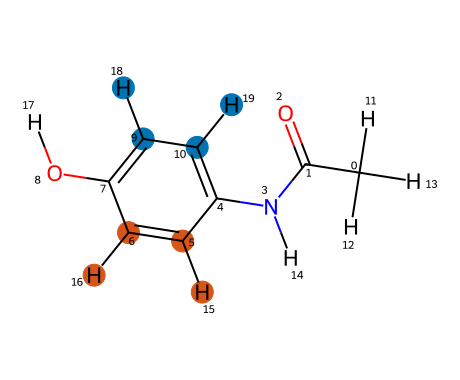

In [7]:
info = draw_symmetry_operation(descriptor, 1, output=str(scratch / "ring_exchange.png"))
print("operation 1 exchanges (atom pairs):", info["exchanged_pairs"])
display(Image(filename=str(scratch / "ring_exchange.png")))

The twelve automorphisms collapse to **two operations** on these columns. No selected torsion contains a
methyl hydrogen, so the six methyl permutations act on the descriptor exactly as the identity does, and the
six "methyl permutation x ring flip" exactly as the flip. `sigma` is the column of the original frame that
supplies each column of the relabelled one:

In [8]:
sigma_to_op = {op.sigma: op.index for op in descriptor.operations}
rows = []
for p in enumeration.permutations:
    image = []
    for q in descriptor.quads:
        img = tuple(p[i] for i in q)
        image.append(next(k for k, qq in enumerate(descriptor.quads) if qq in (img, tuple(reversed(img)))))
    rows.append({"H11-H13 go to": tuple(p[11:14]), "ring flipped": p[5] == 10,
                 "action on the columns (sigma)": tuple(image), "descriptor operation": sigma_to_op[tuple(image)]})
pd.DataFrame(rows)

,H11-H13 go to,ring flipped,action on the columns (sigma),descriptor operation
0,"(11, 12, 13)",False,"(0, 1, 2, 3, 4)",0
1,"(11, 13, 12)",False,"(0, 1, 2, 3, 4)",0
2,"(12, 11, 13)",False,"(0, 1, 2, 3, 4)",0
3,"(12, 13, 11)",False,"(0, 1, 2, 3, 4)",0
4,"(13, 11, 12)",False,"(0, 1, 2, 3, 4)",0
5,"(13, 12, 11)",False,"(0, 1, 2, 3, 4)",0
6,"(11, 12, 13)",True,"(0, 3, 4, 1, 2)",1
7,"(11, 13, 12)",True,"(0, 3, 4, 1, 2)",1
8,"(12, 11, 13)",True,"(0, 3, 4, 1, 2)",1
9,"(12, 13, 11)",True,"(0, 3, 4, 1, 2)",1


Why the image is recomputed and not shifted: on these frames the image of `aryl` differs from `aryl` + 180
degrees by the ring distortion.

In [9]:
closed = descriptor.closed_angles(tors, coordinates=cmd, atom_mapping=mapping)
print(f"stored columns agree with the coordinates to {descriptor.stored_agreement_:.2e} rad")
shift = np.rad2deg(wrap(closed[:, 3] - closed[:, 1] - np.pi))
print(f"aryl@1-3-4-10 minus (aryl + 180 deg): mean {shift.mean():+.2f}, sd {shift.std():.2f}, largest {np.abs(shift).max():.1f} deg")

stored columns agree with the coordinates to 2.67e-07 rad
aryl@1-3-4-10 minus (aryl + 180 deg): mean +0.09, sd 7.09, largest 25.4 deg


## 5. The symmetric distance (used by HDBSCAN)

Each column contributes `sqrt(w) (cos θ, sin θ)` to the embedding `Φ(θ)`, so `-π` and `π` are one place, and

```text
d_sym(x, y) = min over g in G of || Φ(x) - Φ(g y) ||
```

where `g y` is `y` with its columns permuted by operation `g`. The one-sided minimum equals the two-sided
`min over g, h of || Φ(g x) - Φ(h y) ||` exactly when every operation is an isometry of the embedding, which
holds because the operations permute columns and the weights are constant on every orbit (section 4). The
cost is `|G|` matrix products: every embedded point has the same norm, so `||a - b||² = 2W - 2 a·b`.

**An operation acts on the whole row.** The flip moves `aryl` and `phenol` together; folding each torsion
into its own period would also identify the configuration where only one of them turned, a different
conformer. Ties go to the earlier operation, identity first. A canonical labelling per frame followed by
ordinary distances is **not** what is done: it breaks pairs that sit on either side of the labelling
boundary.

Two real frames: *x* is the first frame, *y* the frame closest to *x* once relabelled by the flip, among
frames whose stored description is far from *x*.

In [10]:
X = descriptor.embed(closed)
far = np.flatnonzero(np.linalg.norm(X - X[0], axis=1) > 1.0)
flipped = descriptor.embed(descriptor.transform(closed, 1))
i, j = 0, int(far[np.argmin(np.linalg.norm(flipped[far] - X[0], axis=1))])
display(pd.DataFrame(np.rad2deg(closed[[i, j]]), columns=descriptor.names, index=[f"x = frame {i}", f"y = frame {j}"]).round(1))
d_sym, op = descriptor.distance(closed[i], closed[j])
d_two, (g, h) = descriptor.exhaustive_distance(closed[i], closed[j])
print(f"d_sym one-sided = {d_sym:.6f} (operation {op}) | two-sided = {d_two:.6f} (g, h = {g}, {h}) | "
      f"no relabelling = {np.linalg.norm(X[i] - X[j]):.3f}")
flip = descriptor.operations[1].atom_permutation
measured = descriptor.closed_angles(None, coordinates=cmd.xyz[[j]][:, list(flip), :],
                                    box_vectors=cmd.unitcell_vectors[[j]],
                                    atom_mapping=list(range(mol.GetNumAtoms())), topology=cmd.topology)
print("y with its atoms renamed and every column measured again, minus the permuted row (rad):",
      np.round(wrap(measured[0] - descriptor.transform(closed[[j]], 1)[0]), 7))

,omega,aryl,phenol,aryl@1-3-4-10,phenol@9-7-8-17
x = frame 0,155.2,-153.6,-16.4,29.6,167.1
y = frame 2324,158.0,28.9,166.4,-152.4,-17.4


d_sym one-sided = 0.053563 (operation 1) | two-sided = 0.053563 (g, h = 0, 1) | no relabelling = 2.828


y with its atoms renamed and every column measured again, minus the permuted row (rad): [ 1.e-07  0.e+00  0.e+00 -0.e+00 -0.e+00]


Read naively, *x* and *y* differ by about 180 degrees in `aryl` and in `phenol`; *y*'s images are close to
*x*'s columns, and `d_sym` is small. The relabelling is checked against geometry: renaming *y*'s atoms and
measuring again gives the permuted row.

`d_sym` is a minimum over relabellings and not Euclidean in any fixed embedding, so HDBSCAN gets it as an
exact dense matrix. Its use, cost and limits are on the [HDBSCAN](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/hdbscan/) page.

## 6. Symmetry-invariant coordinates (used by torsion partitioning)

[Torsion partitioning](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/torsion-partitioning/) cuts one-dimensional profiles, so it needs coordinates whose
value does not depend on the labelling. A torsion no operation moves is its own coordinate (`omega`). The
torsions one operation moves together form a **coupling group** (`aryl` and `phenol` under the flip); each is
replaced by an average over the group's own operations,

```text
per torsion c:    z_c  = < exp(i m θ_σ(c)) >                 cut on 2θ for a two-fold flip (m images)
per pair a, b:    z_ab = < exp(i (θ_σ(b) - θ_σ(a))) >        the relative orientation, which the flip keeps
```

the average running over the operations that act within the group. `arg z` is the coordinate. A pair whose
two torsions share a central bond is left out: their difference measures the geometry at one atom, not a
rotamer. `|z|` says how well the average is defined; where the images cancel (`|z|` below `z_min`, 0.5) the
frame is left out of that coordinate's profile, and is still assigned by its value if the coordinate is cut.

coupling groups: [{'torsions': ['aryl', 'phenol'], 'operations': 2}]
coordinates: ['omega', '2*aryl', '2*phenol', 'phenol-aryl']
frames with |z| >= z_min, per coordinate: {'omega': np.float64(1.0), '2*aryl': np.float64(1.0), '2*phenol': np.float64(1.0), 'phenol-aryl': np.float64(1.0)}
frames x and y of section 5, coordinates (deg): x [155.2  56.1 -29.3 137.3] | y [158.   56.4 -31.  136.3]


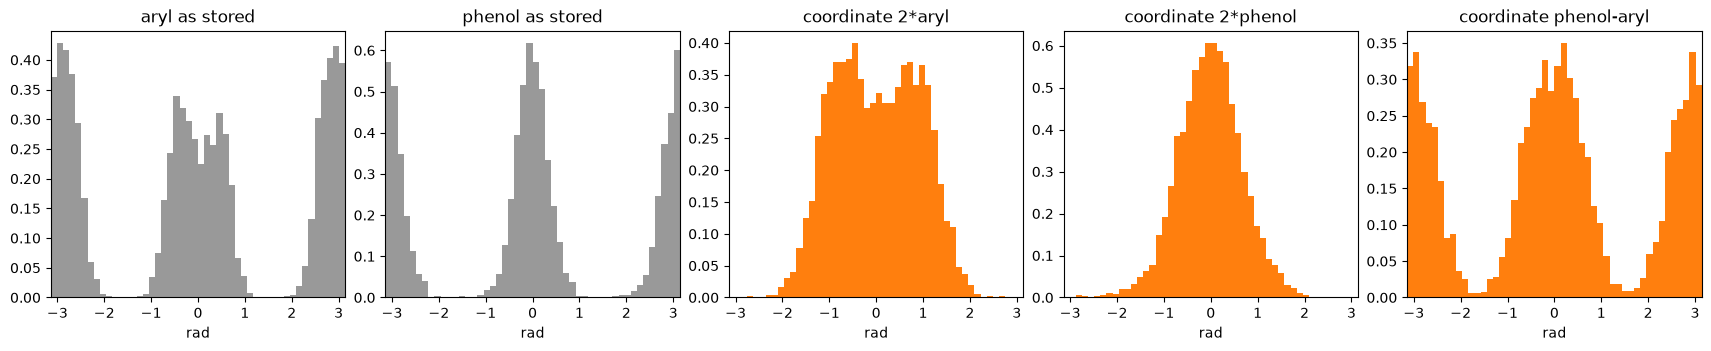

In [11]:
fit = t_hdbscan(tors, molecule=mol, torsion_definitions=definitions, coordinates=cmd, atom_mapping=mapping)
cells = cut_clustering(fit)
Y, valid = cells["coordinate_values"], cells["coordinate_valid"]
print("coupling groups:", cells["coupling_groups"])
print("coordinates:", cells["coordinates"])
print("frames with |z| >= z_min, per coordinate:", dict(zip(cells["coordinates"], valid.mean(axis=0).round(4))))
print(f"frames x and y of section 5, coordinates (deg): x {np.round(np.degrees(Y[i]), 1)} | y {np.round(np.degrees(Y[j]), 1)}")
fig, axes = plt.subplots(1, 2 + len(cells["coordinates"]) - 1, figsize=(17, 3.4), layout="constrained")
for ax, name in zip(axes[:2], ("aryl", "phenol")):
    ax.hist(closed[:, descriptor.names.index(name)], bins=edges, density=True, color="0.6")
    ax.set(title=f"{name} as stored", xlim=(-np.pi, np.pi), xlabel="rad")
for ax, (k, name) in zip(axes[2:], [(k, n) for k, n in enumerate(cells["coordinates"]) if n != "omega"]):
    ax.hist(Y[:, k], bins=edges, density=True, color=palette(1))
    ax.set(title=f"coordinate {name}", xlim=(-np.pi, np.pi), xlabel="rad")
plt.show()

`aryl` and `phenol` as stored each show two peaks half a turn apart. `2*aryl` and `2*phenol` fold them, and
`phenol-aryl` keeps what the folding loses, whether the carbonyl and the hydroxyl hydrogen are on the same
side of the ring or on opposite sides. Frames *x* and *y* of section 5, stored half a turn apart in `aryl` and
`phenol`, have coordinates within 3 degrees of each other, as their small `d_sym` says they should. The `z_min` parameter and its effect are on the [Torsion partitioning](https://csy0000.github.io/MD-tools/openmm_methods/analysis/torsional-clustering/torsion-partitioning/) page.

## 7. One labelling for drawing

Neither method needs a choice of labelling. A histogram does: a stored column of one cluster shows one
conformer written twice. Each frame is written in the labelling **nearest one reference frame**,

```text
g*(x) = argmin over g in G of || Φ(ref) - Φ(g x) ||          frame x is drawn as g*(x) x
```

which picks the one point of each frame's orbit in the **Dirichlet domain** of the reference. The reference is
the **density peak of the largest cluster**, an actual frame (the smallest core distance), never a mean: a
circular mean of a multimodal torsion can describe no configuration. **The margin**, the second-best
operation's distance minus the best, says how arbitrary the choice was for a frame.

**One reference or two levels.** A cluster far from the reference can be equidistant from it in both of its
labellings, and is then cut in two frame by frame. `align_all(per_cluster=True)` aligns each cluster's frames
to the cluster's own density peak, and writes only that peak in the labelling nearest the global reference.
It is the default and costs one extra alignment per cluster. `descriptor.align_to_reference(closed, ref_row)`
is the same rule for any reference row (the torsion partitioning uses it with `reference`).

In [12]:
fit = t_hdbscan(tors, molecule=mol, torsion_definitions=definitions, coordinates=cmd, atom_mapping=mapping).fit()
ref = fit.density_peak(0)
one = {"one reference": fit.align_all(per_cluster=False), "two levels": fit.align_all(per_cluster=True)}
al = one["two levels"]
print(f"reference: frame {ref}, cluster {group_name(int(fit.labels_[ref]))}")
rows = []
for name, a in one.items():
    for c in range(fit.n_clusters_):
        m = fit.labels_ == c
        rows.append({"alignment": name, "cluster": group_name(c),
                     "frames relabelled": round(float((a["operations"][m] != 0).mean()), 3),
                     "mean distance, no relabelling": round(float(a["distance_identity"][m].mean()), 3),
                     "mean distance, nearest": round(float(a["distance"][m].mean()), 3),
                     "frames with margin < 0.1": round(float((a["margin"][m] < 0.1).mean()), 3)})
pd.DataFrame(rows)

reference: frame 3899, cluster A


,alignment,cluster,frames relabelled,"mean distance, no relabelling","mean distance, nearest",frames with margin < 0.1
0,one reference,A,0.547,1.795,0.623,0.000
1,one reference,B,0.473,2.007,1.952,0.578
2,two levels,A,0.547,1.795,0.623,0.000
3,two levels,B,0.434,1.584,0.689,0.000


With one reference, most of cluster B sits on the wall (margin below 0.1): B differs from A by half a turn in
`aryl`, or, written through the flip, by half a turn in `phenol`, and is equidistant from A's peak either way.
With two levels no frame of either cluster is that close to a wall.

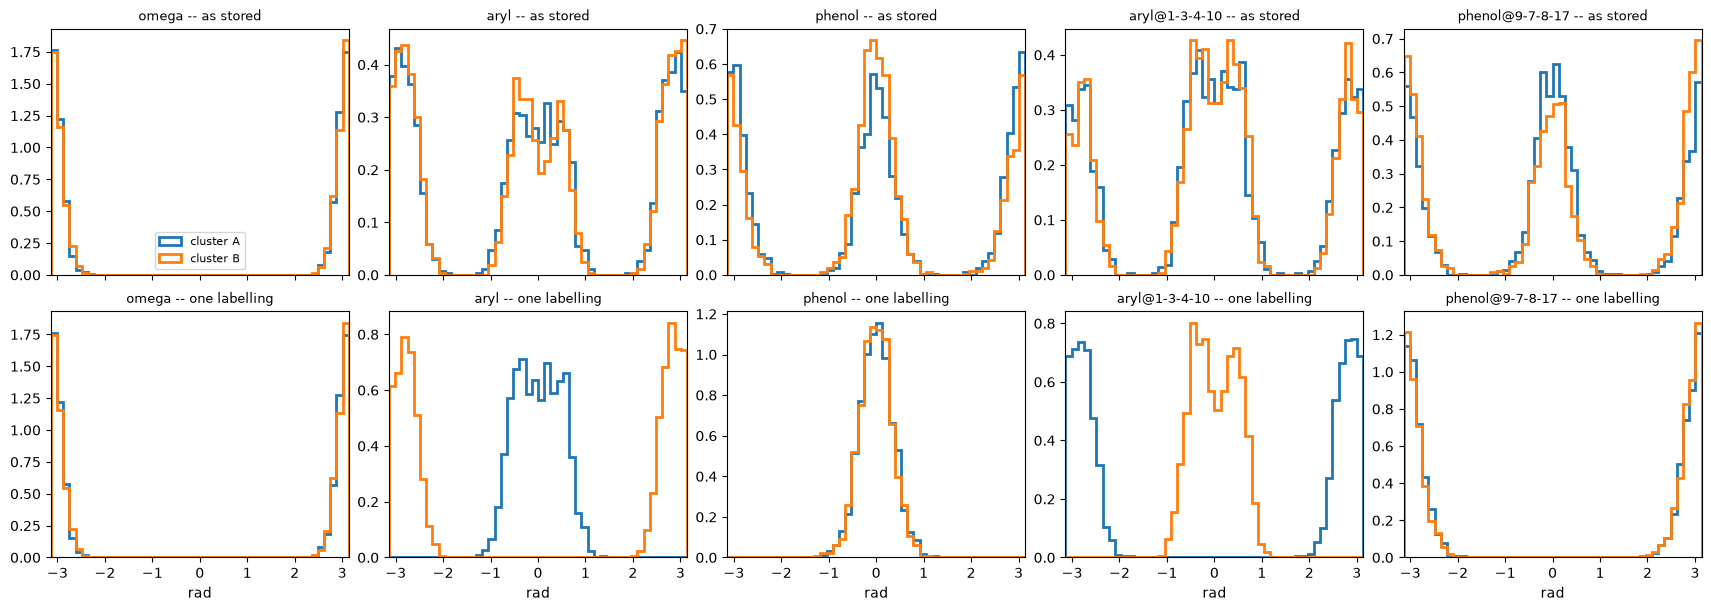

In [13]:
fig, axes = plt.subplots(2, 5, figsize=(17, 6), layout="constrained", sharex=True)
for r, (title, theta) in enumerate((("as stored", fit.closed_theta_), ("one labelling", al["angles"]))):
    for col, name in enumerate(fit.descriptor_.names):
        for k in range(fit.n_clusters_):
            axes[r, col].hist(theta[fit.labels_ == k, col], bins=edges, density=True, histtype="step",
                              lw=2.0, color=palette(k), label=f"cluster {group_name(k)}")
        axes[r, col].set_xlim(-np.pi, np.pi); axes[r, col].set_title(f"{name} -- {title}", fontsize=9)
for col in range(5):
    axes[1, col].set_xlabel("rad")
axes[0, 0].legend(fontsize=8)
plt.show()

**The partner of a ring torsion is not a free torsion.** `aryl@1-3-4-10` stays on the line `aryl + 180` degrees
up to the ring distortion δ, and the flip maps δ to -δ. On this trajectory δ is symmetric about zero (mean
0.1, standard deviation 7.1 degrees), so relabelling leaves its histogram where it was.

**Fold one angle, leave the partner free?** A natural shortcut for a symmetric pair: fold one angle into a
window of width `2π/N` around the reference and leave the other. It is a valid domain only when every frame
has exactly one image in the window. On c(RGDfV) the phenyl ring passes (99.93 % of frames have exactly one
image of `Phe:chi2` in a half-turn window; its two columns are 175 degrees apart) and the valine isopropyl
fails (37.4 % have none; its two methyl torsions are 120 degrees apart). The Dirichlet rule has no such
condition.

### A gauge on one column

A ring flip moves `aryl` **and** `phenol` by half a turn in one step. Folding each into a half-circle on its own
would identify `(0, 0)`, `(0, 180)`, `(180, 0)` and `(180, 180)`, where the flip identifies only `(0, 0)` with
`(180, 180)` and `(0, 180)` with `(180, 0)`: two real conformers merged. What is valid is to **fix the gauge of
one column and let the others follow**: each frame is written with the operation that puts the gauge column in
a window, and every other column goes with it. Give a **width** and the window is centred on the reference's
own value, so the cut falls half a width away, in the gap; `(column, lo, hi)` sets it explicitly.

window: aryl in [-106, 74) deg | in the window: 0.9998 | within 0.1 rad of a cut: 0.0003


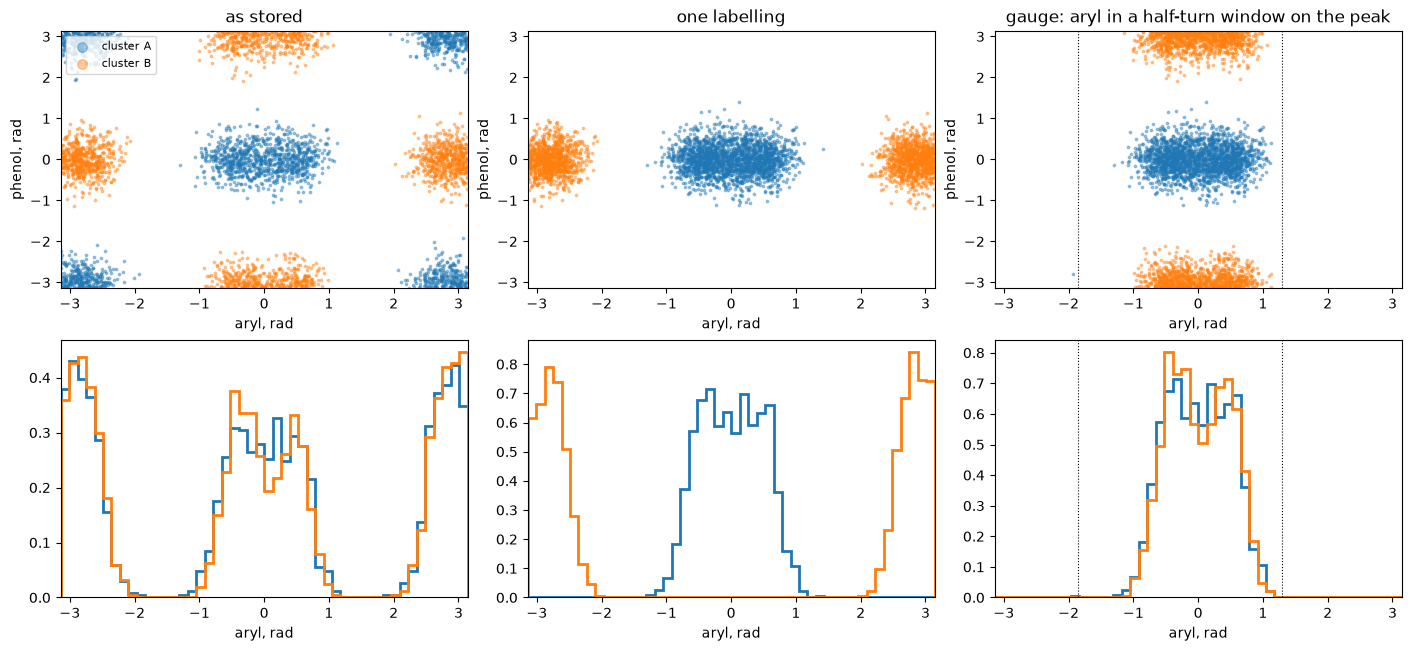

In [14]:
gg = fit.align_all(per_cluster=True, gauge=("aryl", np.pi))     # a half-turn window centred on the peak
_, lo, hi = gg["gauge_window"]
ok, near = gg["gauge_satisfied"], gg["gauge_edge_distance"] < 0.1
print(f"window: aryl in [{np.rad2deg(lo):.0f}, {np.rad2deg(hi):.0f}) deg | in the window: {ok.mean():.4f} "
      f"| within 0.1 rad of a cut: {near.mean():.4f}")
ia, ip = fit.descriptor_.names.index("aryl"), fit.descriptor_.names.index("phenol")
fig, axes = plt.subplots(2, 3, figsize=(14, 6.4), layout="constrained")
versions = (("as stored", fit.closed_theta_), ("one labelling", al["angles"]),
            ("gauge: aryl in a half-turn window on the peak", gg["angles"]))
for col, (title, th) in enumerate(versions):
    for k in range(fit.n_clusters_):
        sel = fit.labels_ == k
        axes[0, col].scatter(th[sel, ia], th[sel, ip], s=3, alpha=0.4, color=palette(k), label=f"cluster {group_name(k)}")
        axes[1, col].hist(th[sel, ia], bins=edges, density=True, histtype="step", lw=2.0, color=palette(k))
    axes[0, col].set(xlim=(-np.pi, np.pi), ylim=(-np.pi, np.pi), xlabel="aryl, rad", ylabel="phenol, rad", title=title)
    axes[1, col].set(xlim=(-np.pi, np.pi), xlabel="aryl, rad")
for ax in axes[:, 2]:
    for e in (lo, hi):
        ax.axvline(wrap(e), color="k", lw=0.8, ls=":")
axes[0, 0].legend(markerscale=4, fontsize=8)
plt.show()

Left: as stored, each cluster in two places. Middle: one labelling, cluster B drawn where its own peak is
(`aryl` near 180). Right: the gauge; both clusters sit in the middle of the window and differ where they
really do, in `phenol`. **The gauge is for drawing.** The clustering never sees it: a window has a cut, and two
frames at `aryl` 89 and 91 degrees are one conformer written half a turn apart. A frame on the cut keeps the
operation that lands it nearest the window, with `gauge_satisfied` False, and is never moved silently.
`gauge_edge_distance` belongs beside any figure that uses one.

## 8. A crystal structure, or any other reference

Matching a crystal ligand onto the simulated molecule gives one atom assignment per graph match, so one
structure is several rows of torsions. Two PDB entries hold paracetamol as the ligand `TYL`: 4YJI (an aryl
acylamidase) and 4A9K (the CREBBP bromodomain), bound to a protein and without hydrogens.
`reference_assignments` returns the rows, `descriptor.nearest_labelling(candidates, reference)` chooses the one
nearest a reference over the columns every candidate can measure (a torsion through a hydrogen is NaN), and
`fit.assign_reference` does that per cluster and says which cluster the structure resembles.

In [15]:
from md_tools.analysis import reference_assignments
from rdkit import RDLogger
RDLogger.DisableLog("rdApp.warning")

DATA = pathlib.Path.cwd().parents[2] / "tutorial" / "paracetamol" / "analysis" / "data"
crystals = {pdb: reference_assignments(str(DATA / f"{pdb}_TYL.sdf"), mol, fit.descriptor_.quads) for pdb in ("4YJI", "4A9K")}
display(pd.DataFrame([{"crystal": pdb, "assignment": k,
                       **{n: (round(float(np.rad2deg(v)), 1) if np.isfinite(v) else "n/a (through H)")
                          for n, v in zip(fit.descriptor_.names, row)}}
                      for pdb, r in crystals.items() for k, row in enumerate(r)]))
for pdb, r in crystals.items():
    out = fit.assign_reference(r)
    print(f"{pdb}: columns compared {out['columns_used']}; best cluster {out['best_cluster']}; "
          f"consistent with {[group_name(c) for c in out['consistent_with']]}")

,crystal,assignment,omega,aryl,phenol,aryl@1-3-4-10,phenol@9-7-8-17
0,4YJI,0,-179.7,53.6,n/a (through H),-127.8,n/a (through H)
1,4YJI,1,-179.7,-127.8,n/a (through H),53.6,n/a (through H)
2,4A9K,0,-179.4,-173.1,n/a (through H),5.4,n/a (through H)
3,4A9K,1,-179.4,5.4,n/a (through H),-173.1,n/a (through H)


4YJI: columns compared ['omega', 'aryl', 'aryl@1-3-4-10']; best cluster None; consistent with ['A', 'B']
4A9K: columns compared ['omega', 'aryl', 'aryl@1-3-4-10']; best cluster None; consistent with ['A', 'B']


Two assignments per crystal, half a turn apart in `aryl`. **Neither crystal can be assigned to A or B**: on the
columns a crystal can measure, the density peaks of A and B coincide once the flip is applied; they differ
only in `phenol`, through the hydroxyl hydrogen. `assign_reference` checks this and returns no best cluster
rather than an arbitrary nearer one.

## 9. Symmetry-corrected RMSD

The same minimum over the symmetry operations, with a superposition in place of the circle embedding:

```text
RMSD_sym(x, y) = min over g in G of  min over rotations R, translations t of  RMSD(x, R g y + t)
```

For a fixed `g` the optimal rotation is Kabsch's, so the minimum over operations of the Kabsch RMSD is the
global minimum over rotation and permutation together. `operations_on_atoms` restricts the whole-molecule
permutations to the chosen atoms (2 on paracetamol's 11 heavy atoms, 16 on c(RGDfV)'s 41), and refuses an
atom set that is not a union of symmetry orbits. About 2.6 µs per pair and operation in numpy.
`intercluster_rmsd` gives the mean and standard deviation between and within clusters, subsampling large
clusters (`max_per_cluster`, seeded). spyrmsd agrees to 0.002 A on c(RGDfV); cpptraj `symmrmsd` gave values
**below** the valid minimum on 29 of 100 frames once polar hydrogens were added, so it is not a reference here.

In [16]:
from md_tools.analysis import heavy_atoms, operations_on_atoms, intercluster_rmsd

heavy = heavy_atoms(mol)
operations = operations_on_atoms(enumeration, heavy)
Xh = cmd.xyz[:, heavy, :] * 10.0                                    # nm -> A
corrected = intercluster_rmsd(Xh, fit.labels_, operations, max_per_cluster=None)
by_index = intercluster_rmsd(Xh, fit.labels_, operations[:1], max_per_cluster=None)
names_c = [group_name(c) for c in corrected["clusters"]]
table = lambda r: pd.DataFrame([[f"{r['mean'][a, b]:.2f} +- {r['std'][a, b]:.2f}" for b in range(len(names_c))]
                                for a in range(len(names_c))], index=names_c, columns=names_c)
print(f"{len(heavy)} heavy atoms, {corrected['n_operations']} operations")
print("symmetry-corrected (A):"); display(table(corrected))
print("by atom index (A):"); display(table(by_index))

11 heavy atoms, 2 operations
symmetry-corrected (A):


,A,B
A,0.32 +- 0.15,0.32 +- 0.15
B,0.32 +- 0.15,0.32 +- 0.15


by atom index (A):


,A,B
A,0.64 +- 0.35,0.64 +- 0.35
B,0.64 +- 0.35,0.64 +- 0.35


By atom index every entry is about twice as large: the ring flip alone makes one conformer look different
from itself. Corrected, A against B is as close as A against A, because the two clusters differ only in the
hydroxyl hydrogen, which a heavy-atom RMSD does not see.

## What this does and does not establish

* **Structural, not thermodynamic.** A graph automorphism says two configurations are one conformer under
  another naming. It does not make their populations equal: an atom-specific restraint or a REST2 region
  covering one side breaks the energetic symmetry and leaves the graph unchanged (`broken_by=[...]`).
* **The operations are permutations, never reflections**: matching is stereo-aware, so a mirror image is not
  an automorphism. A permutation that swaps two columns fixes the frames where they are equal, and those
  frames are nearly equidistant to two labellings; the margin reports them.
* **The reference changes where a cluster is drawn**, never the clusters, their frames or their populations.
* **Tautomers are not symmetries**, and canonicalization does not make them one.